In [1]:
import empiricaldist
import janitor
import matplotlib.pyplot as plt
import numpy as np
import palmerpenguins
import pandas as pd
import scipy.stats
import seaborn as sns
import sklearn.metrics
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats as ss
import session_info

In [2]:
#ESTABLECER UNA APARIENCIA GENERAL DE LOS GRAFICOS

%matplotlib inline
sns.set_style(style='whitegrid')
sns.set_context(context='notebook')
plt.rcParams['figure.figsize'] = (11, 9.4)

penguin_color = {
    'Adelie': '#ff6602ff',
    'Gentoo': '#0f7175ff',
    'Chinstrap': '#c65dc9ff'
}

In [3]:
preprocessed_penguins_df = pd.read_csv('https://raw.githubusercontent.com/allisonhorst/palmerpenguins/master/inst/extdata/penguins.csv') #Datos preprocesados
processed_penguins_df= preprocessed_penguins_df.dropna()
processed_penguins_df.head(2)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007


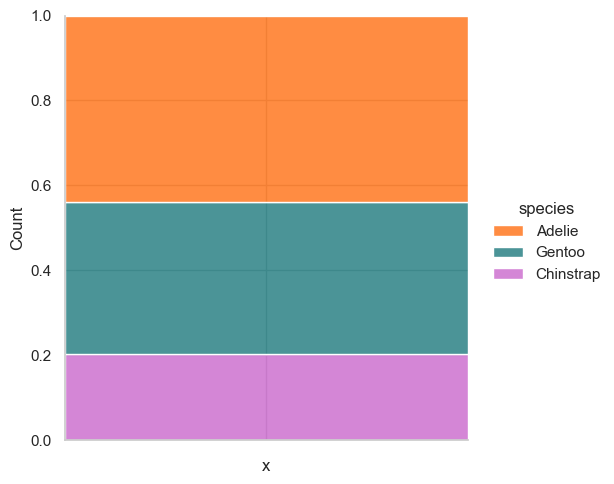

In [25]:
#CONTEOS Y PROPORCIONES

processed_penguins_df.describe(include= "all") #Describir todas las variables
processed_penguins_df.describe() #Describir solo las variables numericas
processed_penguins_df.describe(include= object) #Describir solo las variables categoricas

processed_penguins_df.species.value_counts() #Contar valores
#processed_penguins_df.species.value_counts().plot(kind= "bar") #Graficarlos
#sns.catplot(data= processed_penguins_df, x="species", kind= "count", palette= penguin_color) # Otra forma

#Visualizar las proporciones
(
    processed_penguins_df
    .add_column("x", "")
    .pipe(
        lambda df: (
            sns.displot(
                data= df,
                x= "x",
                hue= "species",
                multiple= "fill",
                palette= penguin_color
            )
        )
    )
)

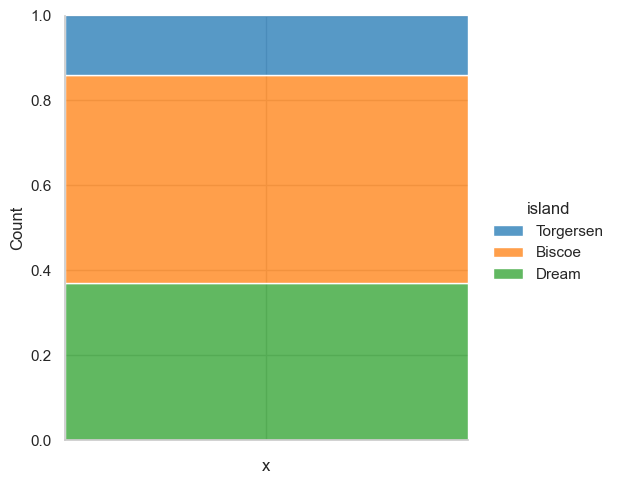

In [40]:
processed_penguins_df.island.value_counts()
#processed_penguins_df.island.value_counts(sort= True).plot(kind="bar")
#sns.catplot(data= processed_penguins_df, x= "island", kind= "count")

(
    processed_penguins_df
    .add_column("x","")
    .pipe(
        lambda df: (
            sns.displot(
                data= df,
                x= "x",
                hue= "island",
                multiple= "fill"
            )
        )
    )
    
)

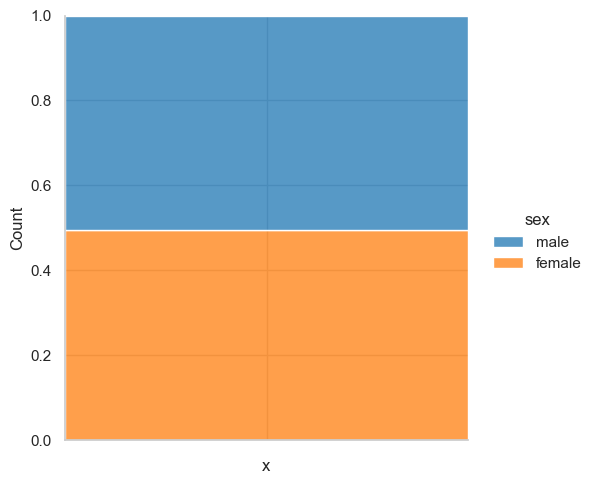

In [51]:
processed_penguins_df.sex.value_counts()
#processed_penguins_df.sex.value_counts().plot(kind= "bar")
#sns.catplot(data= processed_penguins_df, x= "sex", kind= "count")

(
    processed_penguins_df
    .add_column("x","").
    pipe(
        lambda df: (
            sns.displot(
                data= df,
                x= "x",
                hue= "sex",
                multiple= "fill"
            )
        )
    )

)

In [63]:
#MEDIDAS DE TENDENCIA CENTRAL

processed_penguins_df.bill_depth_mm.mean() #media
np.mean(processed_penguins_df.bill_depth_mm) #media
processed_penguins_df.mean() #calcular la media para todo el conjunto de datos

processed_penguins_df.median() #mediana
processed_penguins_df.mode() #moda

C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_11232\4221330927.py:5: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  processed_penguins_df.mean() #calcular la media para todo el conjunto de datos
C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_11232\4221330927.py:7: FutureWarning: The default value of numeric_only in DataFrame.median is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  processed_penguins_df.median() #mediana


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Biscoe,41.1,17.0,190.0,3800.0,male,2009


C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_7812\2710417743.py:4: FutureWarning: The default value of numeric_only in DataFrame.std is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  processed_penguins_df.std()
C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_7812\2710417743.py:5: FutureWarning: The default value of numeric_only in DataFrame.quantile is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  interquartile_range= processed_penguins_df.quantile(0.75) - processed_penguins_df.quantile(0.25)  #rango intercuartilico
C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_7812\2710417743.py:9: FutureWarning: The default value of numeric_only in DataFrame.quantile is deprecated. In a future version, it will default to False. Select o

<Axes: xlabel='flipper_length_mm'>

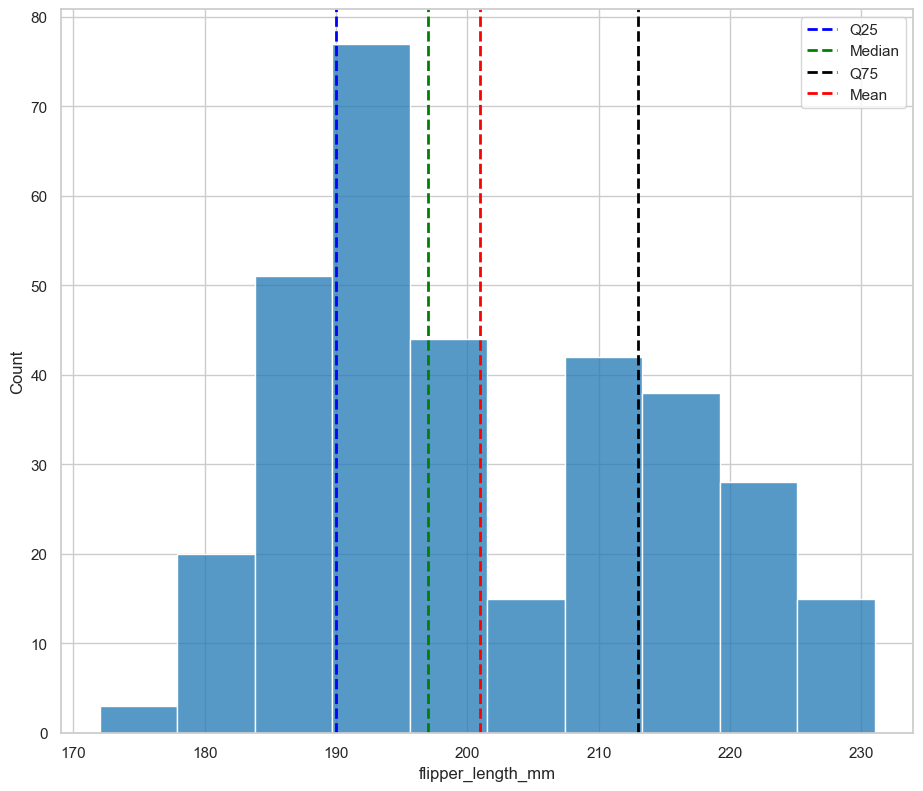

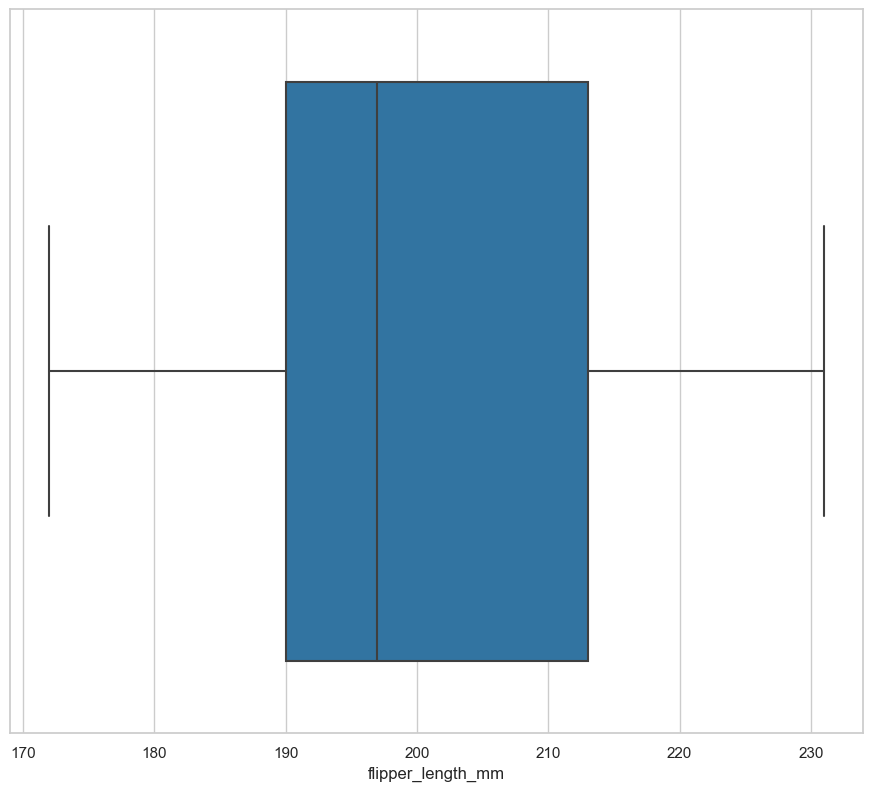

In [32]:
#MEDIDAS DE DISPERSION

range= processed_penguins_df.max(numeric_only= True) - processed_penguins_df.min(numeric_only= True)
processed_penguins_df.std()
interquartile_range= processed_penguins_df.quantile(0.75) - processed_penguins_df.quantile(0.25)  #rango intercuartilico

(
    processed_penguins_df
    .quantile(q=[0.75, 0.5, 0.25])
    .transpose()
    .rename_axis("variable") #asignar el nombre "variable" al índice del df
    .reset_index() #reiniciar el índice del df para convertirlo en una columna
    .assign(
        iqr= lambda df: df[0.75] - df[0.25]
    )
)

#Graficar 
sns.histplot(processed_penguins_df, x= "flipper_length_mm") 

#Agregar todos los cuartiles
quartiles= [0.25, 0.5, 0.75]
name_labels= ["Q25", "Median", "Q75"]
colors= ["blue", "green", "black"]

for i,j,z in zip(quartiles, name_labels, colors):
    plt.axvline(processed_penguins_df.flipper_length_mm.quantile(i), 
            color= z, 
            linestyle= "dashed", #trazar una linea que muestre el promedio en el histograma anterior
            linewidth= 2,
            label= j) 

plt.axvline(processed_penguins_df.flipper_length_mm.mean(), 
            color= "red", 
            linestyle= "dashed", #trazar una linea que muestre el promedio en el histograma anterior
            linewidth= 2,
            label= "Mean") 

plt.legend();


plt.figure() #Para agregar una grafica completamente nueva y no se sobreponga con la anterior
sns.boxplot(processed_penguins_df, x= "flipper_length_mm")


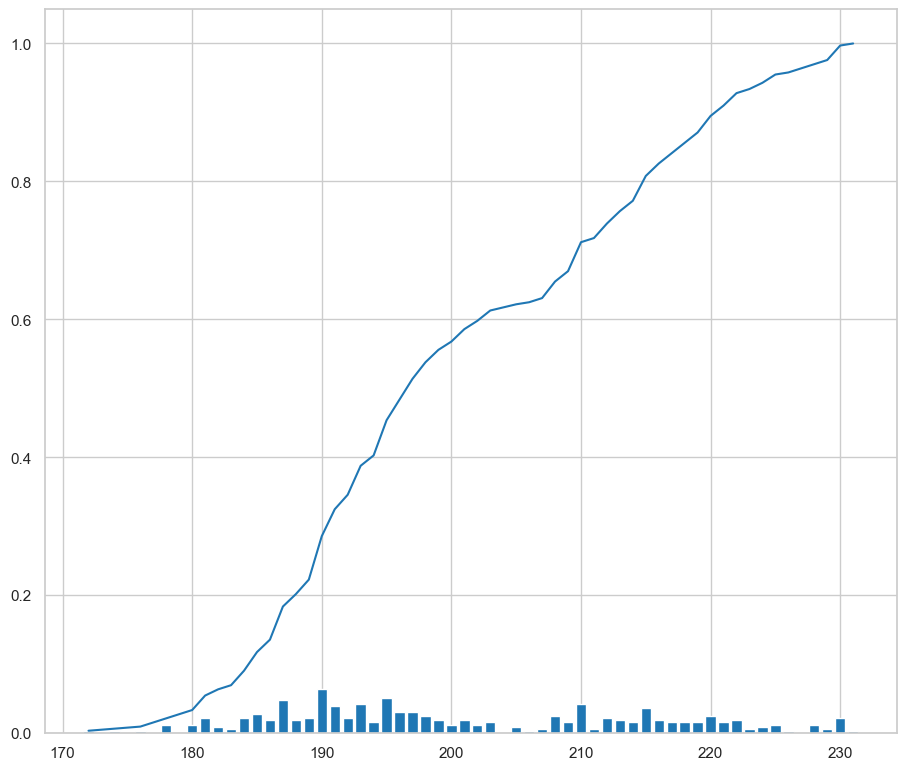

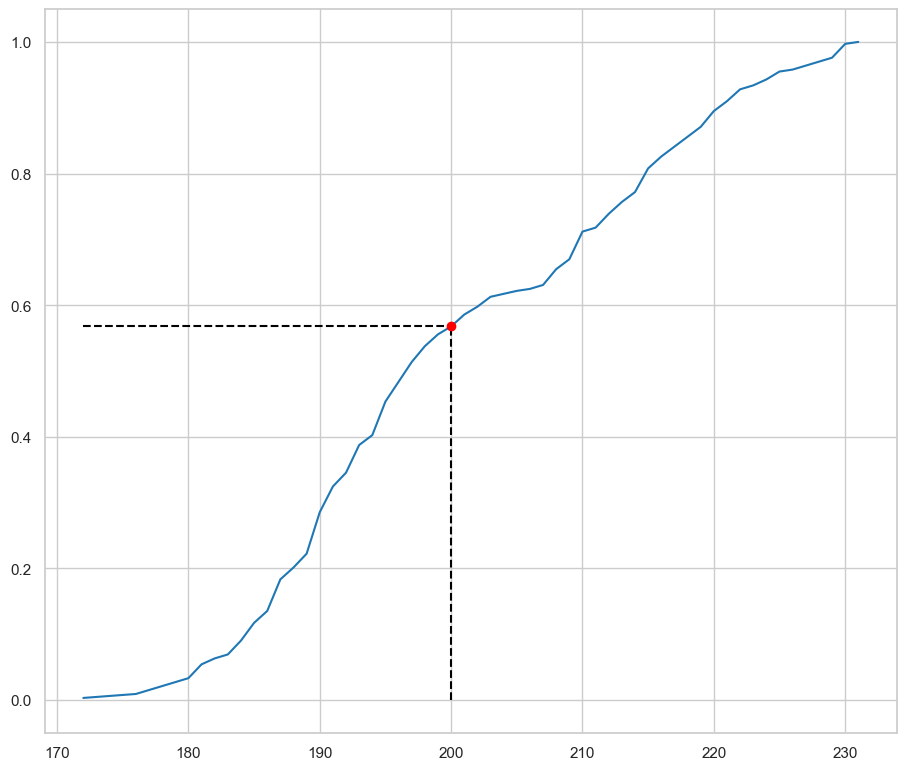

In [4]:
#Funciones de probabilidad de masas (PMFs)

pmf_flipper_length_mm= empiricaldist.Pmf.from_seq(processed_penguins_df.flipper_length_mm, normalize= True) #Obtener las probabilidades
pmf_flipper_length_mm.bar() #visualizar
pmf_flipper_length_mm(190) #preguntar por una probabilidad

#Funciones empirícas de probabilidad acumulada (ECDFs)

#sns.ecdfplot(processed_penguins_df, x="flipper_length_mm")
cdf_flipper_length_mm= empiricaldist.Cdf.from_seq(processed_penguins_df.flipper_length_mm, normalize= True) 
cdf_flipper_length_mm.plot() #visualizar
cdf_flipper_length_mm.forward(200) #preguntar por la probabilidad acumulada

#añadir una linea guia para visualizar los valores
plt.figure()
cdf_flipper_length_mm.plot()

q = 200 # Specify quantity
p = cdf_flipper_length_mm.forward(q)

plt.vlines( x=q, ymin=0, ymax=p, color = 'black', linestyle='dashed')
plt.hlines( y=p, xmin=pmf_flipper_length_mm.qs[0], xmax=q, color='black', linestyle='dashed')
plt.plot(q, p, 'ro')

#Comparar distribuciones de probabilidad

#sns.ecdfplot(processed_penguins_df, x= "flipper_length_mm", hue= "species", palette= penguin_color)

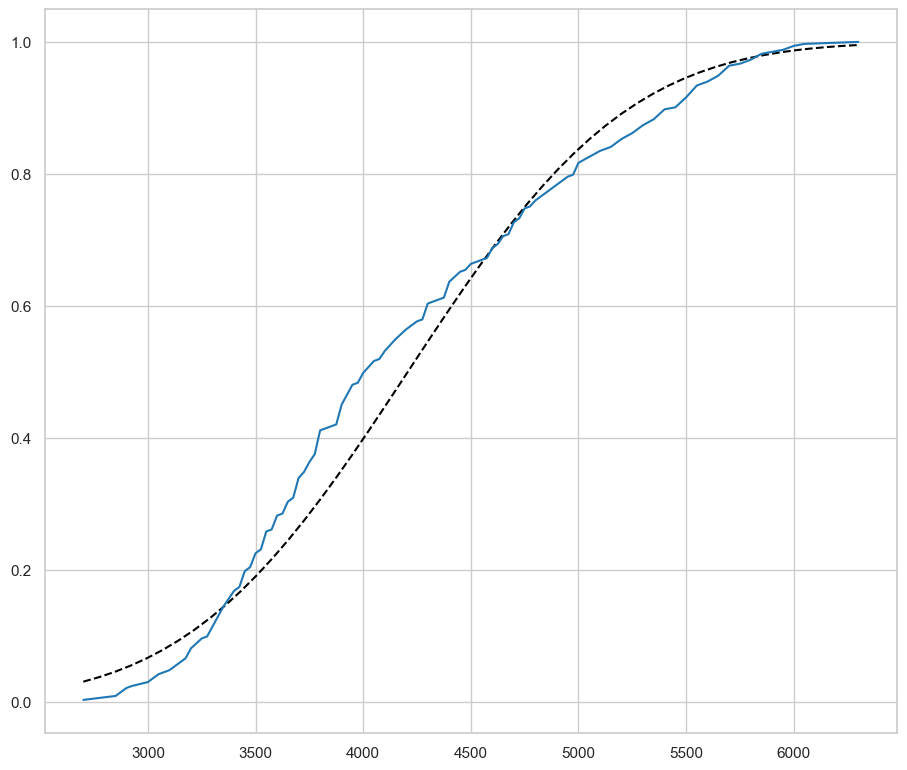

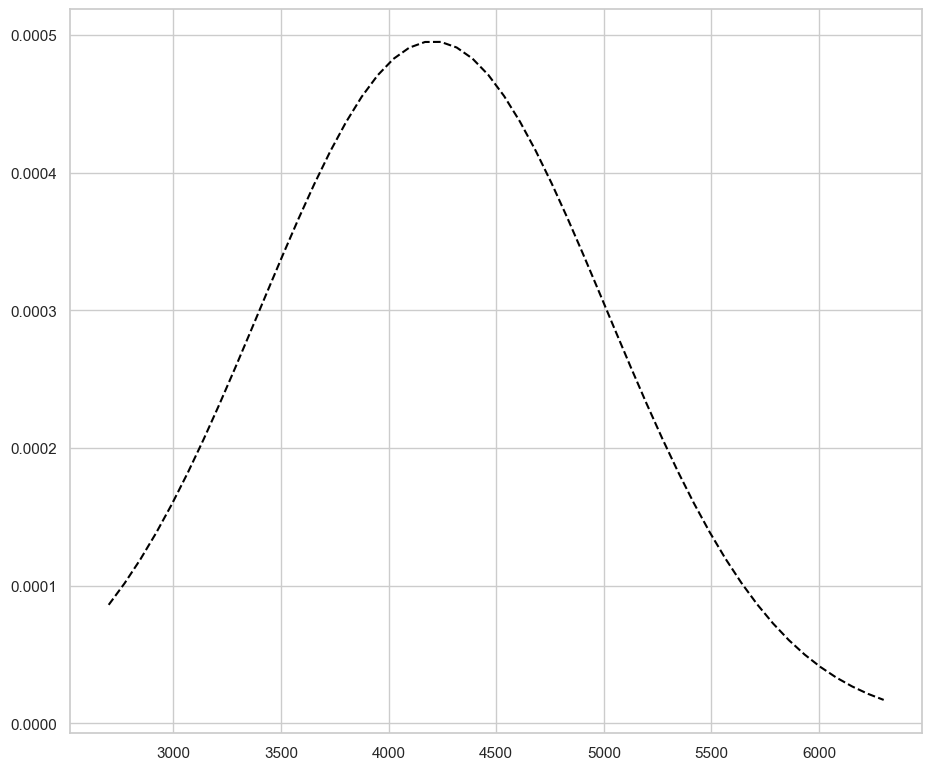

In [5]:
#Funciones de densidad de probabilidad

#sns.kdeplot(data= processed_penguins_df, x= "flipper_length_mm")

stats= processed_penguins_df.body_mass_g.describe()

#Generar datos aleatorios para comparar la distribucion acumulada de los datos
xs= np.linspace(stats["min"], stats["max"])
ys= scipy.stats.norm(stats["mean"], stats["std"]).cdf(xs)

plt.plot(xs,ys, color= "black", linestyle = "dashed") #Los datos deberian lucir asi si tuvieran distribucion normal

empiricaldist.Cdf.from_seq(processed_penguins_df.body_mass_g, normalize= True).plot()

#Generar datos aleatorios para comparar la distribucion de densidad de probabilidad de los datos
plt.figure()
xs= np.linspace(stats["min"], stats["max"])
ys= scipy.stats.norm(stats["mean"], stats["std"]).pdf(xs)

plt.plot(xs,ys, color= "black", linestyle = "dashed") #Los datos deberian lucir asi si tuvieran distribucion normal

#sns.kdeplot(processed_penguins_df, x="body_mass_g")